# Task 3: adversarial attacks with ART (Adversarial Robustness Toolbox)

In Example 1 we wrote PGD by hand. ART ships ready implementations of many attacks.
Here we:
1. train a small MNIST CNN and compare several ART evasion attacks on it
   (white-box: FGSM, BIM, PGD, DeepFool, Carlini-Wagner L2; black-box: Square Attack),
2. repeat the targeted panda -> gibbon attack from Example 1 with ART's PGD.

In [1]:
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets

from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import (
    ...
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
np.random.seed(0)

/home/mwm/repositories/teaching/AISEC2026_win_private/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1: MNIST model

In [2]:
train_dataset = datasets.MNIST('../data/downloads', train=True, download=True)
test_dataset = datasets.MNIST('../data/downloads', train=False, download=True)

x_train = (train_dataset.data.numpy() / 255.0).astype('float32')[:, None]
y_train = train_dataset.targets.numpy()
x_test = (test_dataset.data.numpy() / 255.0).astype('float32')[:, None]
y_test = test_dataset.targets.numpy()
print(x_train.shape, x_test.shape)

(60000, 1, 28, 28) (10000, 1, 28, 28)


In [3]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        # ... conv to 64
        # pool 2x2
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(..., 128)
        self.fc2 = nn.Linear(128, ...)

    def forward(self, x):
        x = F.relu(...)
        x = F.relu(...)
        x = self.dropout1(self.pool(x))
        x = torch.flatten(x, 1)
        x = self.dropout2(F.relu(self.fc1(x)))
        return self.fc2(x)


model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

ART wraps the model in an *estimator*. The wrapper knows the input shape, number of classes
and valid pixel range (`clip_values`), and it can also train the model for us.

In [4]:
classifier = PyTorchClassifier(
    model=model,
    loss=criterion,
    optimizer=optimizer,
    input_shape=(1, 28, 28),
    nb_classes=10,
    clip_values=(0.0, 1.0),
    device_type="gpu" if device.type == "cuda" else "cpu",
)
classifier.fit(x_train, y_train, batch_size=128, nb_epochs=2)

In [5]:
def accuracy(x, y):
    return (classifier.predict(x, batch_size=256).argmax(1) == y).mean()


print(f"Clean test accuracy: {accuracy(x_test, y_test) * 100:.2f}%")

Clean test accuracy: 98.58%


## Part 2: comparing attacks

All attacks share the same interface: `attack.generate(x)` returns adversarial examples.
We use the same 200 test images for each attack, and an L-inf budget of `eps = 0.2`
for the gradient-sign attacks. DeepFool and C&W are minimum-norm attacks: they don't take
an `eps`, they search for the smallest perturbation that flips the label.

Clean accuracy on these 200 images: 100.00%


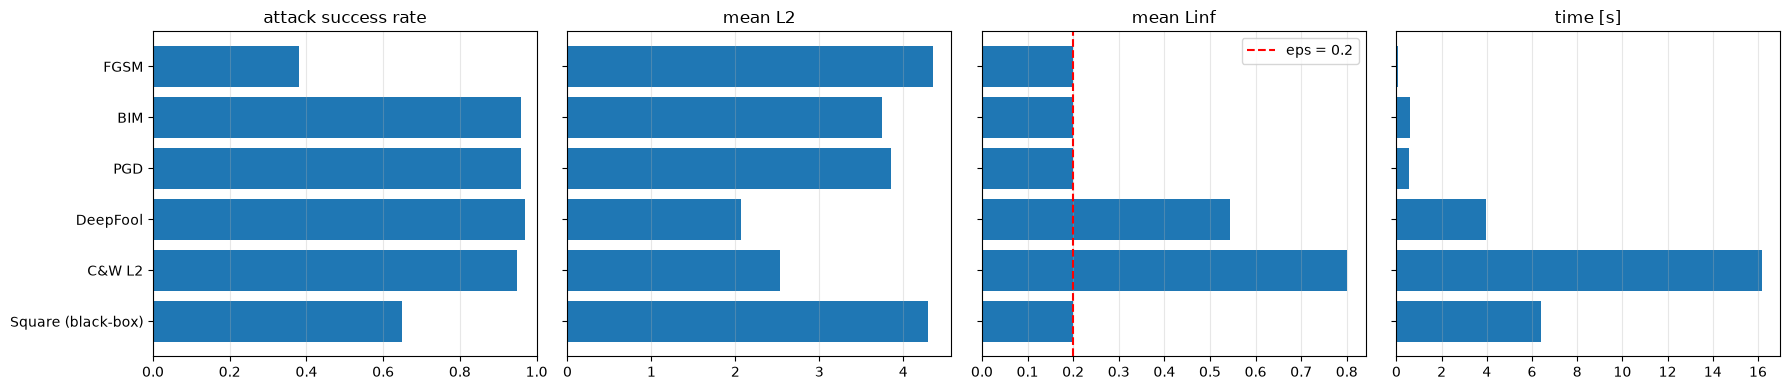

In [6]:
n = 200
x_eval, y_eval = x_test[:n], y_test[:n]
eps = 0.2

attacks = {
    "FGSM": ...,
    "BIM": ...,
    "PGD": ...,
    "DeepFool": ...,
    "C&W L2": ...,
    "Square (black-box)": ...,
}

# success rate only counts images the model got right before the attack
clean_correct = classifier.predict(x_eval, batch_size=256).argmax(1) == y_eval

results, adv_examples = [], {}
for name, attack in attacks.items():
    start = time.time()
    x_adv = attack.generate(x=x_eval)
    elapsed = time.time() - start
    delta = (x_adv - x_eval).reshape(n, -1)
    adv_examples[name] = x_adv
    results.append({
        "attack": name,
        "attack success rate": (...).mean(),
        "mean L2": np.linalg.norm(delta, ord=2, axis=1).mean(),
        "mean Linf": np.abs(delta).max(axis=1).mean(),
        "time [s]": elapsed,
    })

results = pd.DataFrame(results).set_index("attack")
print(f"Clean accuracy on these {n} images: {accuracy(x_eval, y_eval) * 100:.2f}%")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, column in zip(axes, results.columns):
    ax.barh(results.index, results[column], color="tab:blue")
    ax.set_title(column)
    ax.invert_yaxis()
    ax.grid(True, axis="x", alpha=0.3)
axes[0].set_xlim(0, 1)
axes[2].axvline(eps, color="red", linestyle="--", label=f"eps = {eps}")
axes[2].legend()
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
plt.show()

Success rate alone doesn't say which attack is better: a big enough change fools any model
(just paint a different digit). So we also report how big the perturbation was:
- **L-inf**: the largest change of any single pixel. FGSM/BIM/PGD/Square are limited to `eps = 0.2` here.
- **L2**: the overall size of the change across all pixels (Euclidean length of the difference).

Things to notice:
- iterative attacks (BIM, PGD) are much stronger than single-step FGSM with the same `eps`,
- DeepFool and C&W reach high success with a much smaller L2 perturbation, but they aren't bounded in L-inf,
- Square Attack uses only model outputs (no gradients) and still works, it just needs many more queries.

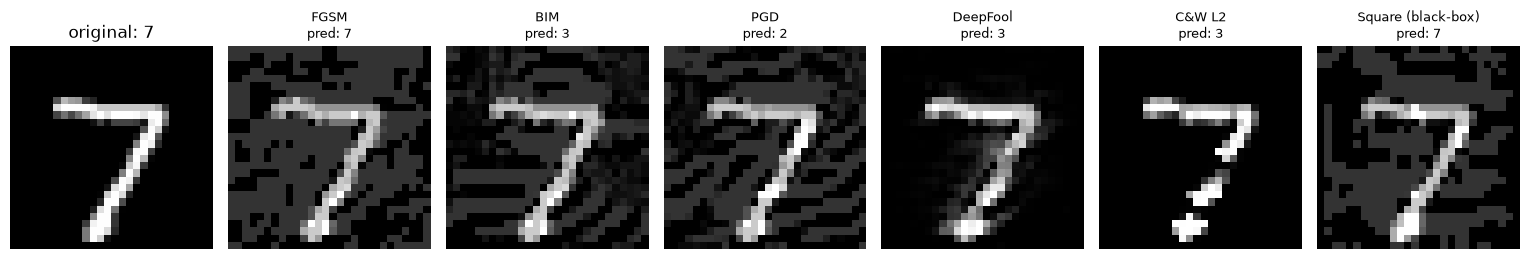

In [7]:
idx = 0
fig, axes = plt.subplots(1, len(attacks) + 1, figsize=(2.2 * (len(attacks) + 1), 2.8))
axes[0].imshow(x_eval[idx, 0], cmap="gray")
axes[0].set_title(f"original: {y_eval[idx]}")
for ax, (name, x_adv) in zip(axes[1:], adv_examples.items()):
    pred = classifier.predict(x_adv[idx:idx + 1]).argmax()
    ax.imshow(x_adv[idx, 0], cmap="gray")
    ax.set_title(f"{name}\npred: {pred}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part 3: Example 1 again, with ART

The panda -> gibbon attack from Example 1, now with several ART attacks on the full-size ConvNext.
PGD uses the same settings as our hand-written version.
ART can do the ImageNet normalization itself through `preprocessing=(mean, std)`,
so we don't need our `normalize()` function. The HuggingFace model returns an object,
so we wrap it to return plain logits.

In [8]:
import torchvision.transforms as T
from PIL import Image
from transformers import ConvNextForImageClassification

class_idx = json.load(open("../data/downloads/imagenet_class_index.json"))
HFmodel = ConvNextForImageClassification.from_pretrained("facebook/convnext-base-384-22k-1k").eval()


class LogitsOnly(nn.Module):
    def __init__(self, hf_model):
        super().__init__()
        ...

    def forward(self, x):
        return ...


image = Image.open('../data/images/960px-Grosser_Panda.JPG')
torch_original = T.Resize([480, 640])(T.ToTensor()(image))
x_panda = torch_original.unsqueeze(0).numpy()

panda_classifier = PyTorchClassifier(
    ...
)

ground_truth_id, target_id = 388, 368
base_prediction = panda_classifier.predict(x_panda).argmax()
print(f"Base prediction: {base_prediction} {class_idx[str(base_prediction)]}")

Loading weights:   0%|          | 0/344 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 344/344 [00:00<00:00, 57269.21it/s]

Base prediction: 388 ['n02510455', 'giant_panda']


FGSM, BIM, PGD and C&W are *targeted*: we pass the one-hot target (gibbon) as `y`.
DeepFool and ART's Square Attack are untargeted only (DeepFool pushes the image over the nearest
decision boundary, Square treats `y` as the true label), so they succeed if the panda becomes *anything* else.

In [9]:
panda_eps = 4 / 255
target = np.zeros((1, 1000), dtype=np.float32)
target[0, target_id] = 1

panda_attacks = {
    "FGSM": ...,
    "BIM": ...,
    "PGD": ...,
    "C&W L2": ...,
    "DeepFool (untargeted)": ...,
    "Square (black-box, untargeted)": ...
}

panda_results = {}
for name, (attack, y) in panda_attacks.items():
    start = time.time()
    x_adv = attack.generate(x=x_panda, y=y)
    elapsed = time.time() - start
    prediction = panda_classifier.predict(x_adv).argmax()
    delta = x_adv - x_panda
    success = prediction == target_id if y is not None else prediction != ground_truth_id
    panda_results[name] = dict(x_adv=x_adv, prediction=prediction, success=success,
                               l2=np.linalg.norm(delta), linf=np.abs(delta).max(), time=elapsed)
    print(f"{name:32s} prediction: {prediction} {class_idx[str(prediction)][1]:20s} "
          f"success: {success}  Linf: {np.abs(delta).max() * 255:.1f}/255  time: {elapsed:.1f}s")

FGSM                             prediction: 388 giant_panda          success: False  Linf: 4.0/255  time: 0.3s


BIM                              prediction: 368 gibbon               success: True  Linf: 4.0/255  time: 2.7s


PGD                              prediction: 368 gibbon               success: True  Linf: 4.0/255  time: 2.7s


C&W L2                           prediction: 368 gibbon               success: True  Linf: 14.1/255  time: 73.5s


DeepFool (untargeted)            prediction: 297 sloth_bear           success: True  Linf: 3.9/255  time: 16.4s


Square (black-box, untargeted)   prediction: 388 giant_panda          success: False  Linf: 4.0/255  time: 57.5s


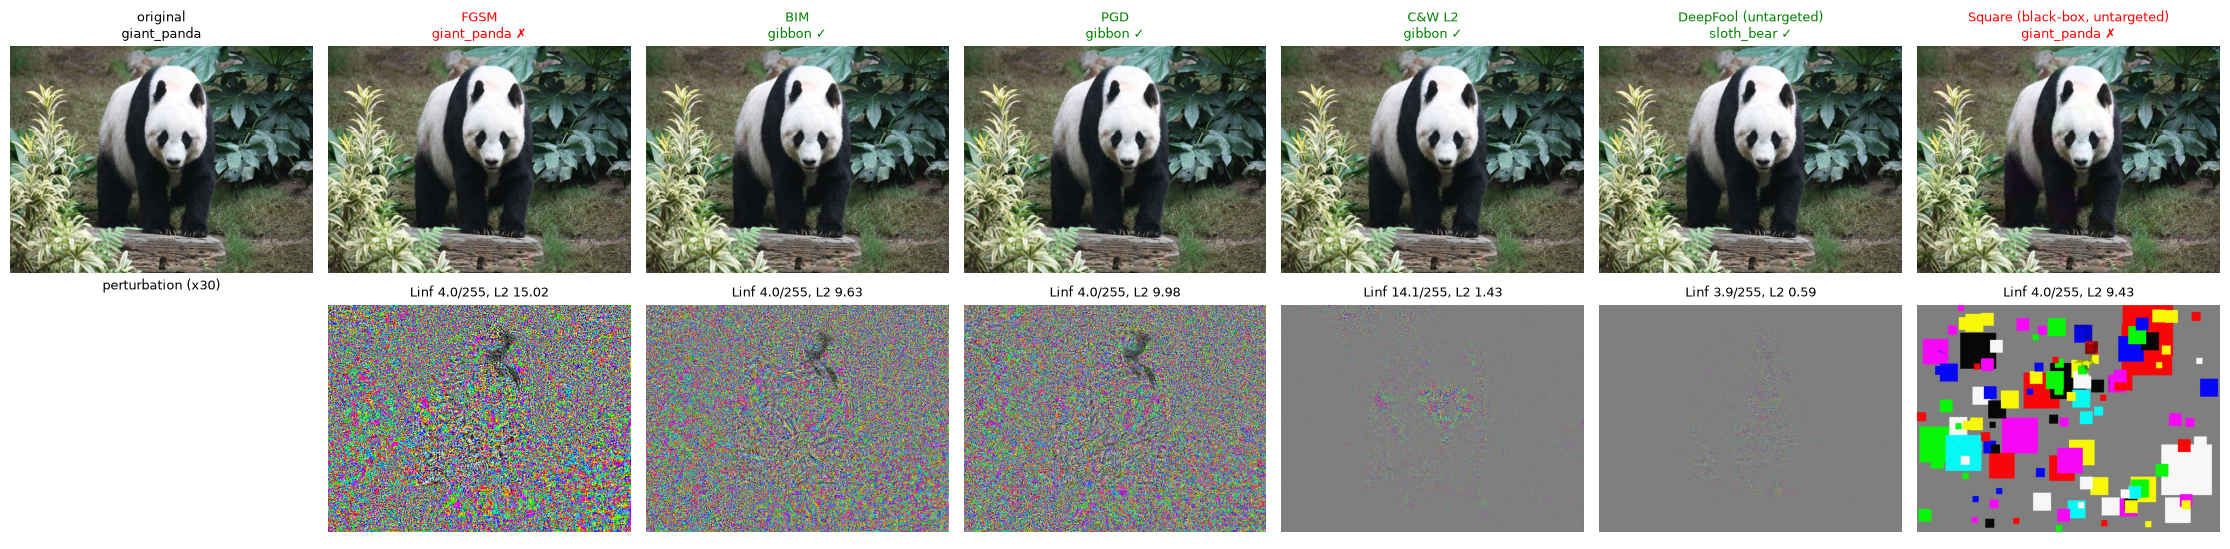

In [10]:
n_cols = len(panda_results) + 1
fig, axes = plt.subplots(2, n_cols, figsize=(3.2 * n_cols, 5.5))
axes[0, 0].imshow(x_panda[0].transpose(1, 2, 0))
axes[0, 0].set_title(f"original\n{class_idx[str(base_prediction)][1]}", fontsize=9)
axes[1, 0].set_title("perturbation (x30)", fontsize=9)
for col, (name, r) in enumerate(panda_results.items(), start=1):
    axes[0, col].imshow(r["x_adv"][0].transpose(1, 2, 0))
    axes[0, col].set_title(f"{name}\n{class_idx[str(r['prediction'])][1]} {'✓' if r['success'] else '✗'}",
                           fontsize=9, color="green" if r["success"] else "red")
    # amplify the perturbation around grey so it is visible
    axes[1, col].imshow(np.clip(0.5 + 30 * (r["x_adv"][0] - x_panda[0]), 0, 1).transpose(1, 2, 0))
    axes[1, col].set_title(f"Linf {r['linf'] * 255:.1f}/255, L2 {r['l2']:.2f}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()